In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

I0000 00:00:1791910218.743918    5125 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791910219.239275    5125 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791910222.589775    5125 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


          MODEL 1
Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 12s 27ms/step - accuracy: 0.9330 - loss: 0.2253 - val_accuracy: 0.9847 - val_loss: 0.0564
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.9806 - loss: 0.0629 - val_accuracy: 0.9872 - val_loss: 0.0458
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.9868 - loss: 0.0425 - val_accuracy: 0.9870 - val_loss: 0.0409
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.9903 - loss: 0.0322 - val_accuracy: 0.9917 - val_loss: 0.0351
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.9920 - loss: 0.0257 - val_accuracy: 0.9890 - val_loss: 0.0399

       MODEL 1 RESULTS
Test Accuracy : 98.78%
Test Loss     : 0.0350


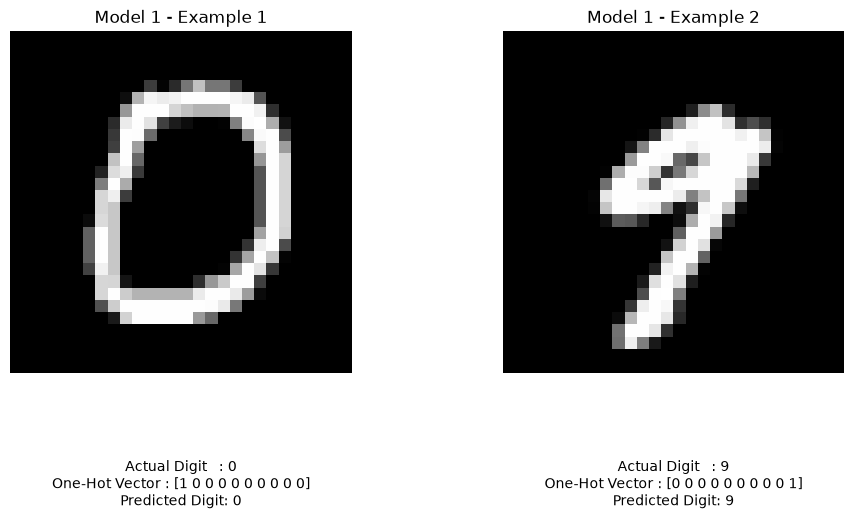



          MODEL 2
Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 12s 27ms/step - accuracy: 0.9057 - loss: 0.3108 - val_accuracy: 0.9832 - val_loss: 0.0615
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.9703 - loss: 0.1001 - val_accuracy: 0.9857 - val_loss: 0.0464
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.9786 - loss: 0.0731 - val_accuracy: 0.9893 - val_loss: 0.0390
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.9820 - loss: 0.0596 - val_accuracy: 0.9887 - val_loss: 0.0366
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - accuracy: 0.9844 - loss: 0.0524 - val_accuracy: 0.9893 - val_loss: 0.0350

       MODEL 2 RESULTS
Test Accuracy : 98.98%
Test Loss     : 0.0309


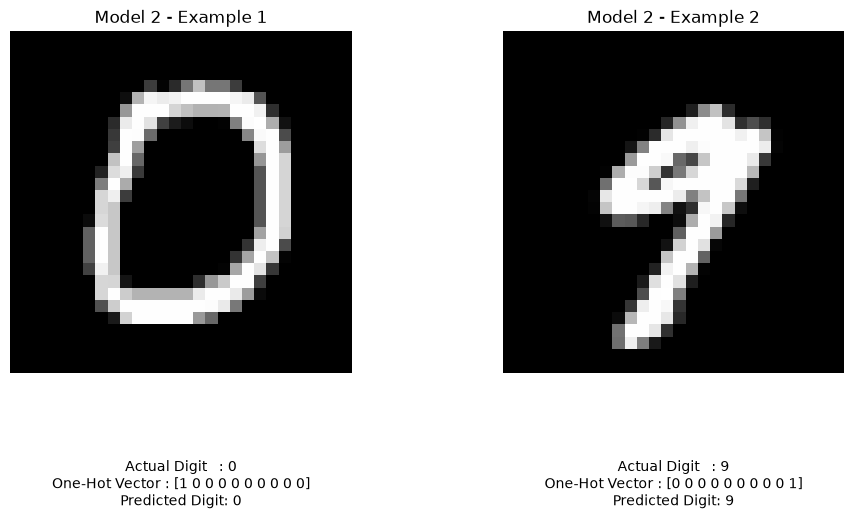

In [3]:

(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

print("================================")
print("          MODEL 1")
print("================================")

model1 = models.Sequential([
    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        input_shape=(28, 28, 1)
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dense(
        10,
        activation="softmax"
    )
])

model1.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model1.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

loss1, accuracy1 = model1.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\n================================")
print("       MODEL 1 RESULTS")
print("================================")
print(f"Test Accuracy : {accuracy1 * 100:.2f}%")
print(f"Test Loss     : {loss1:.4f}")

indices = [10, 20]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for i, index in enumerate(indices):

    image = X_test[index]

    prediction = model1.predict(
        image.reshape(1, 28, 28, 1),
        verbose=0
    )

    predicted_digit = np.argmax(prediction)
    actual_digit = np.argmax(y_test[index])
    one_hot_vector = y_test[index]

    axes[i].imshow(
        image.reshape(28, 28),
        cmap="gray"
    )

    axes[i].set_title(
        f"Model 1 - Example {i + 1}",
        fontsize=12
    )

    axes[i].axis("off")

    result_text = (
        f"Actual Digit   : {actual_digit}\n"
        f"One-Hot Vector : {one_hot_vector.astype(int)}\n"
        f"Predicted Digit: {predicted_digit}"
    )

    axes[i].text(
        0.5,
        -0.25,
        result_text,
        transform=axes[i].transAxes,
        ha="center",
        va="top",
        fontsize=10
    )

plt.tight_layout()
plt.show()


print("\n\n================================")
print("          MODEL 2")
print("================================")

model2 = models.Sequential([
    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        input_shape=(28, 28, 1)
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.5),

    layers.Dense(
        10,
        activation="softmax"
    )
])

model2.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model2.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

loss2, accuracy2 = model2.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\n================================")
print("       MODEL 2 RESULTS")
print("================================")
print(f"Test Accuracy : {accuracy2 * 100:.2f}%")
print(f"Test Loss     : {loss2:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for i, index in enumerate(indices):

    image = X_test[index]

    prediction = model2.predict(
        image.reshape(1, 28, 28, 1),
        verbose=0
    )

    predicted_digit = np.argmax(prediction)
    actual_digit = np.argmax(y_test[index])
    one_hot_vector = y_test[index]

    axes[i].imshow(
        image.reshape(28, 28),
        cmap="gray"
    )

    axes[i].set_title(
        f"Model 2 - Example {i + 1}",
        fontsize=12
    )

    axes[i].axis("off")

    result_text = (
        f"Actual Digit   : {actual_digit}\n"
        f"One-Hot Vector : {one_hot_vector.astype(int)}\n"
        f"Predicted Digit: {predicted_digit}"
    )

    axes[i].text(
        0.5,
        -0.25,
        result_text,
        transform=axes[i].transAxes,
        ha="center",
        va="top",
        fontsize=10
    )

plt.tight_layout()
plt.show()